# Day 8 — Multiple Plots 📊
Today, we’ll learn how to create multiple visualizations efficiently using Seaborn. Since you’ve already learned themes, palettes, and dashboard customization, we’ll build on those skills.

**Learning objectives**
- Understand `sns.pairplot()`
- Learn `sns.jointplot()`
- Learn `sns.FacetGrid()`
- Build a multi-plot dashboard
- Practice with prediction questions and a quiz

## Import Dataset 

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("tips")

print(sns.__version__)
print(df.shape)

df.head()

0.13.2
(244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


## Lesson 1 — Pairplot
### 1. Explanation
A **pairplot** displays relationships between multiple numerical columns in a dataset. It creates scatter plots for pairs of variables and distribution plots along the diagonal.

For this lesson, we’ll use the familiar Seaborn tips dataset.

### 2. Plotting

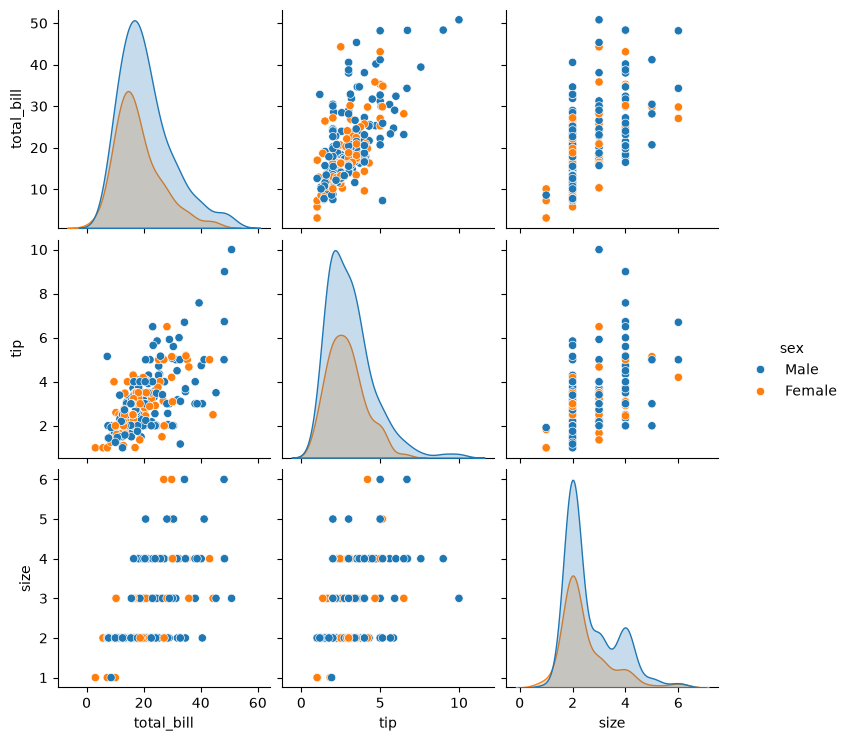

In [3]:
sns.pairplot(
    data=df,
    vars=["total_bill", "tip", "size"],
    hue="sex"
)

plt.show()

**Understand the parameters**
| Parameter | Purpose |
| :--- | :--- |
| `data=df` | Supplies the dataset |
| `vars=[...]` | Selects numerical columns |
| `hue="sex"` | Colors observations by sex |
| `plt.show()` | Displays the plots |

### 3. Output
- The diagonal contains distributions of individual variables.
- The off-diagonal cells show relationships between pairs of variables.
- Different colors distinguish the categories in sex.
- The same variable pair appears in mirrored positions across the grid.

For three selected variables, the pairplot creates a 3 × 3 grid containing 9 panels.

### 4. Prediction

In [4]:

from IPython.display import HTML, display

display(HTML("""
<div id="pairplot-quiz" style="font-family:Arial,sans-serif; max-width:700px;">
    <p>Predict the output before running the code!</p>

    <form id="quiz-form">
        <div style="margin-bottom:20px;">
            <p><b>Q1. If you select four numerical variables, how many panels will a pairplot create?</b></p>
            <label><input type="radio" name="q1" value="a"> A. 4</label><br>
            <label><input type="radio" name="q1" value="b"> B. 8</label><br>
            <label><input type="radio" name="q1" value="c"> C. 16</label>
            <p id="feedback1"></p>
        </div>

        <hr>

        <div style="margin-bottom:20px;">
            <p><b>Q2. What does hue="sex" do in sns.pairplot()?</b></p>
            <label><input type="radio" name="q2" value="a"> A. Removes the sex column</label><br>
            <label><input type="radio" name="q2" value="b"> B. Colors observations according to sex categories</label><br>
            <label><input type="radio" name="q2" value="c"> C. Creates only one plot</label>
            <p id="feedback2"></p>
        </div>

        <hr>

        <div style="margin-bottom:20px;">
            <p><b>Q3. What appears along the diagonal of a typical pairplot?</b></p>
            <label><input type="radio" name="q3" value="a"> A. Distributions of individual variables</label><br>
            <label><input type="radio" name="q3" value="b"> B. Only legends</label><br>
            <label><input type="radio" name="q3" value="c"> C. Correlation coefficients only</label>
            <p id="feedback3"></p>
        </div>

        <button type="button" id="submit-quiz"
            style="padding:10px 18px; background:#2563eb; color:white;
            border:none; border-radius:6px; cursor:pointer;">
            Submit Answers
        </button>

        <button type="button" id="reset-quiz"
            style="padding:10px 18px; margin-left:8px; border:1px solid #999;
            border-radius:6px; cursor:pointer;">
            Reset
        </button>
    </form>

    <h3 id="score" aria-live="polite"></h3>
</div>

<script>
(function() {
    const root = document.getElementById("pairplot-quiz");
    if (!root || root.dataset.initialized) return;
    root.dataset.initialized = "true";

    const answers = {
        q1: {
            correct: "c",
            explanation: "Four variables create a 4 × 4 grid = 16 panels."
        },
        q2: {
            correct: "b",
            explanation: "hue='sex' assigns different colors to the sex categories."
        },
        q3: {
            correct: "a",
            explanation: "The diagonal displays each variable's distribution."
        }
    };

    root.querySelector("#submit-quiz").addEventListener("click", function() {
        let score = 0;

        Object.keys(answers).forEach(function(q, index) {
            const selected = root.querySelector('input[name="' + q + '"]:checked');
            const feedback = root.querySelector("#feedback" + (index + 1));

            if (!selected) {
                feedback.innerHTML = "⚠️ Please select an answer.";
                feedback.style.color = "#b45309";
            } else if (selected.value === answers[q].correct) {
                score++;
                feedback.innerHTML = "✅ Correct! " + answers[q].explanation;
                feedback.style.color = "#15803d";
            } else {
                feedback.innerHTML = "❌ Incorrect. " + answers[q].explanation;
                feedback.style.color = "#dc2626";
            }
        });

        root.querySelector("#score").textContent =
            "Your Score: " + score + "/3 " +
            (score === 3 ? "🎉 Excellent!" :
             score === 2 ? "👍 Good job!" : "💪 Keep practicing!");
    });

    root.querySelector("#reset-quiz").addEventListener("click", function() {
        root.querySelector("#quiz-form").reset();

        [1, 2, 3].forEach(function(i) {
            root.querySelector("#feedback" + i).textContent = "";
        });

        root.querySelector("#score").textContent = "";
    });
})();
</script>
"""))


## Lesson 2 — Jointplot
### 1. Explanation
A jointplot visualizes the relationship between two variables and their individual distributions in one figure.

For example, we can investigate whether customers who have higher total bills also tend to leave larger tips.

<table>
	<tr>
		<td style="width: 40%; vertical-align: top;">
			<img src="../Images/Seaborn_29.png" alt="Scatter plot" style="border-radius: 20px; width:
					100%;">
		</td>
		<td style="width: 40%; vertical-align: top;">
			<img src="../Images/Seaborn_30.png" alt="Scatter plot" style="border-radius: 20px; width:
					100%;">
		</td>
	</tr>
</table>

A typical jointplot has three main parts:
- **Center:** shows the relationship between two variables.
- **Top:** shows the distribution of the x-axis variable.
- **Right:** shows the distribution of the y-axis variable.

### 2. Plotting

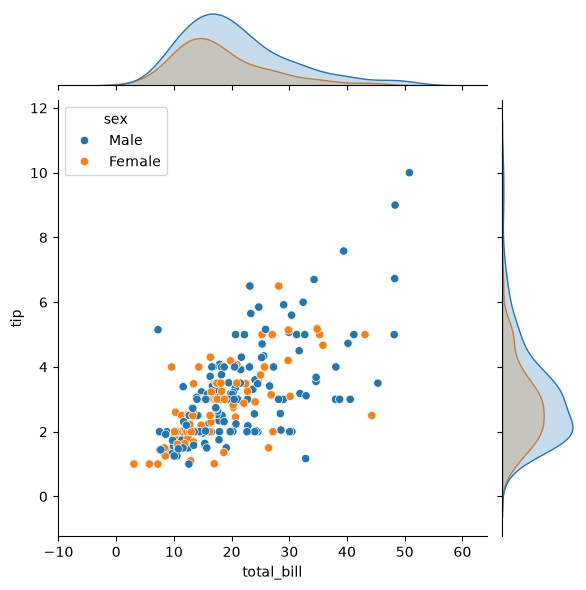

In [5]:
sns.jointplot(
    data=df,
    x="total_bill",
    y="tip",
    kind="scatter",
    hue="sex"
)

plt.show()

**Understanding the parameters**
| Parameter | Purpose |
| :--- | :--- |
| `data=df` | Specifies the dataset |
| `x="total_bill"` | Variable on the x-axis |
| `y="tip"` | Variable on the y-axis |
| `kind="scatter"` | Creates a central scatter plot |
| `hue="sex"` | Colors observations by category |

**Important:** `jointplot()` creates and manages its own figure, so it doesn't accept an ordinary Matplotlib `ax=` argument like `sns.scatterplot()` does.

### 3. Types
**Explore different jointplot**\
You can change the central visualization using kind.

<table>
	<tr>
		<td style="width: 40%; vertical-align: top;">
			<img src="../Images/Seaborn_31.png" alt="Scatter joint plot" style="border-radius: 20px; width:
					100%;">
		</td>
		<td style="vertical-align: center; padding-left: 15px;">
			<h3>Scatter — <span style="background-color: rgba(128, 128, 128, 0.3); padding: 2px 4px;">kind="scatter"</span></h3>
			<p>Displays individual observations and helps 
				reveal relationships, clusters, and 
				outliers.</p>
		</td>
	</tr>
	<tr>
		<td style="width: 40%; vertical-align: top;">
			<img src="../Images/Seaborn_32.png" alt="Regression joint plot" style="border-radius: 20px; width:
					100%;">
		</td>
		<td style="vertical-align: center; padding-left: 15px;">
			<h3>Regression — <span style="background-color: rgba(128, 128, 128, 0.3); padding: 2px 4px;">kind="reg"</span></h3>
			<p>Adds a fitted regression line to help 
				identify the overall linear trend.</p>
		</td>
	</tr>
	<tr>
		<td style="width: 40%; vertical-align: top;">
			<img src="../Images/Seaborn_33.png" alt="Hexbin joint plot" style="border-radius: 20px; width:
					100%;">
		</td>
		<td style="vertical-align: center; padding-left: 15px;">
			<h3>Hexbin — <span style="background-color: rgba(128, 128, 128, 0.3); padding: 2px 4px;">kind="hex"</span></h3>
			<p>Groups observations into hexagonal bins. 
				Useful when many points overlap.</p>
		</td>
	</tr>
</table>

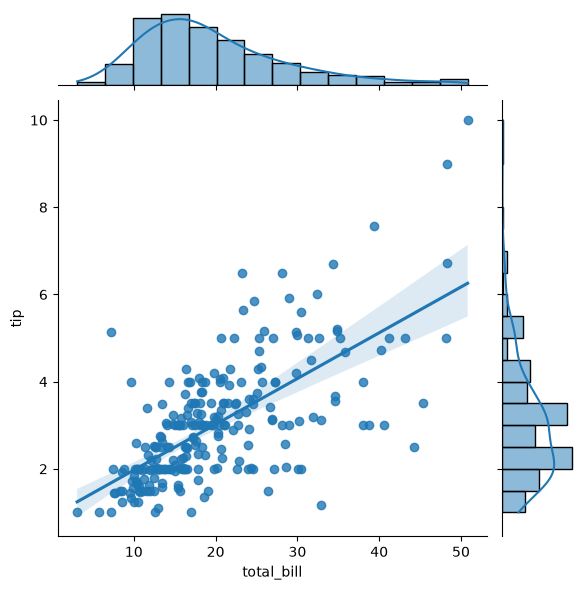

In [6]:
# Regression
sns.jointplot(
    data=df,
    x="total_bill",
    y="tip",
    kind="reg"
)

plt.show()

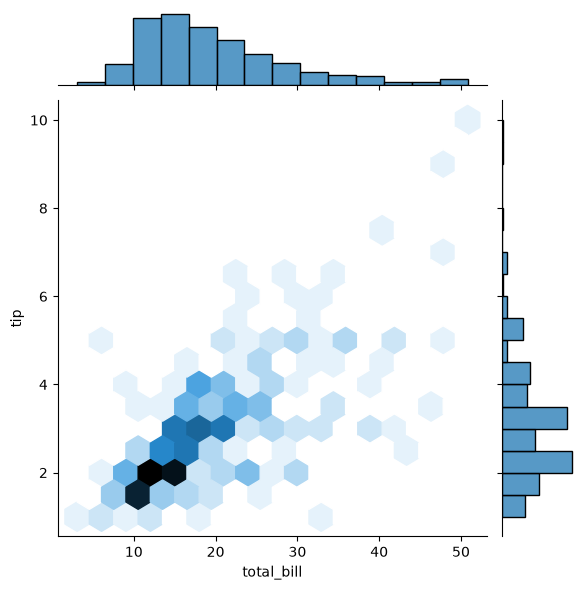

In [7]:
# Hexbin
sns.jointplot(
    data=df,
    x="total_bill",
    y="tip",
    kind="hex"
)

plt.show()

### 4. Prediction

In [8]:

from IPython.display import HTML, display

display(HTML("""
<div id="jointplot-quiz" style="font-family:Arial,sans-serif; max-width:700px;">
    <p>Predict the output before running the code!</p>

    <form id="quiz-form">
        <div style="margin-bottom:20px;">
            <p><b>Q1. What makes sns.jointplot() different from a basic scatterplot?</b></p>
            <label><input type="radio" name="q1" value="a"> A. It only displays a histogram.</label><br>
            <label><input type="radio" name="q1" value="b"> B. It combines a central relationship plot with marginal distributions.</label><br>
            <label><input type="radio" name="q1" value="c"> C. It only works with categorical data.</label>
            <p id="feedback1"></p>
        </div>

        <hr>

        <div style="margin-bottom:20px;">
            <p><b>Q2. Which kind adds a fitted regression line?</b></p>
            <label><input type="radio" name="q2" value="a"> A. kind="hex"</label><br>
            <label><input type="radio" name="q2" value="b"> B. kind="scatter"</label><br>
            <label><input type="radio" name="q2" value="c"> C. kind="reg"</label>
            <p id="feedback2"></p>
        </div>

        <hr>

        <div style="margin-bottom:20px;">
            <p><b>Q3. Your scatterplot contains thousands of overlapping points. Which type may help show point density?</b></p>
            <label><input type="radio" name="q3" value="a"> A. kind="hex"</label><br>
            <label><input type="radio" name="q3" value="b"> B. kind="reg"</label><br>
            <label><input type="radio" name="q3" value="c"> C. kind="scatter"</label>
            <p id="feedback3"></p>
        </div>

        <button type="button" id="submit-quiz"
            style="padding:10px 18px; background:#2563eb; color:white;
            border:none; border-radius:6px; cursor:pointer;">
            Submit Answers
        </button>

        <button type="button" id="reset-quiz"
            style="padding:10px 18px; margin-left:8px;
            border:1px solid #999; border-radius:6px; cursor:pointer;">
            Reset
        </button>
    </form>

    <h3 id="score" aria-live="polite"></h3>
</div>

<script>
(function() {
    const root = document.getElementById("jointplot-quiz");
    if (!root || root.dataset.initialized) return;
    root.dataset.initialized = "true";

    const answers = {
        q1: {
            correct: "b",
            explanation: "A jointplot combines a central relationship plot with distributions along the margins."
        },
        q2: {
            correct: "c",
            explanation: 'kind="reg" adds a fitted regression line.'
        },
        q3: {
            correct: "a",
            explanation: 'kind="hex" groups observations into hexagonal bins to show density.'
        }
    };

    root.querySelector("#submit-quiz").addEventListener("click", function() {
        let score = 0;

        Object.keys(answers).forEach(function(q, index) {
            const selected = root.querySelector(
                'input[name="' + q + '"]:checked'
            );
            const feedback = root.querySelector("#feedback" + (index + 1));

            if (!selected) {
                feedback.innerHTML = "⚠️ Please select an answer.";
                feedback.style.color = "#b45309";
            } else if (selected.value === answers[q].correct) {
                score++;
                feedback.innerHTML = "✅ Correct! " + answers[q].explanation;
                feedback.style.color = "#15803d";
            } else {
                feedback.innerHTML = "❌ Incorrect. " + answers[q].explanation;
                feedback.style.color = "#dc2626";
            }
        });

        root.querySelector("#score").textContent =
            "Your Score: " + score + "/3 " +
            (score === 3 ? "🎉 Excellent!" :
             score === 2 ? "👍 Good job!" : "💪 Keep practicing!");
    });

    root.querySelector("#reset-quiz").addEventListener("click", function() {
        root.querySelector("#quiz-form").reset();

        [1, 2, 3].forEach(function(i) {
            root.querySelector("#feedback" + i).textContent = "";
        });

        root.querySelector("#score").textContent = "";
    });
})();
</script>
"""))


## Lesson 3 — FacetGrid
### 1. Explanation
`FacetGrid()` lets you create multiple separate plots from subsets of a dataset, based on categories such as `sex`, `smoker`, or `time`.

For example, instead of displaying lunch and dinner observations in one plot, we can create separate panels for each meal.

### 2. Plotting

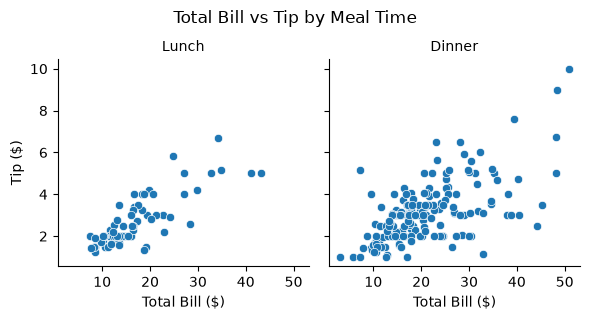

In [9]:
g = sns.FacetGrid(
    data=df,
    col="time"
)

g.map_dataframe(
    sns.scatterplot,
    x="total_bill",
    y="tip"
)

g.set_axis_labels("Total Bill ($)", "Tip ($)")
g.set_titles("{col_name}")
g.figure.suptitle("Total Bill vs Tip by Meal Time", y=1.05)

plt.show()

### 3. Understand the output
You'll see two panels:
- **Lunch:** displays observations where `time == "Lunch"`.
- **Dinner:** displays observations where `time == "Dinner"`.

Both panels use the same variables, but each displays a different subset of the data.

**Important parameters**
| Parameter | Purpose |
| :--- | :--- |
| `col="time"` | Creates separate columns for each meal category |
| `row="sex"` | Creates separate rows for each sex category |
| `hue="smoker"` |Colors observations by smoking category when supplied to the plotting function |
| `map_dataframe()` | Applies a plotting function to each subset |
| `set_axis_labels()` | Sets axis labels for the panels |

You can also try replacing `col="time"` with `col="day"` to create a panel for each day represented in the dataset.

### 4. Prediction

In [10]:

from IPython.display import HTML, display

display(HTML("""
<div id="facetgrid-quiz" style="font-family:Arial,sans-serif; max-width:700px;">
    <p>Predict the output before running the code!</p>

    <form id="quiz-form">
        <div style="margin-bottom:20px;">
            <p><b>Q1. What does col="time" do in sns.FacetGrid()?</b></p>
            <label><input type="radio" name="q1" value="a"> A. Creates separate columns for meal categories</label><br>
            <label><input type="radio" name="q1" value="b"> B. Changes the plot background color</label><br>
            <label><input type="radio" name="q1" value="c"> C. Combines all categories into one panel</label>
            <p id="feedback1"></p>
        </div>

        <hr>

        <div style="margin-bottom:20px;">
            <p><b>Q2. What happens when you use row="sex"?</b></p>
            <label><input type="radio" name="q2" value="a"> A. Observations are sorted by tip amount</label><br>
            <label><input type="radio" name="q2" value="b"> B. Separate rows are created for sex categories</label><br>
            <label><input type="radio" name="q2" value="c"> C. The x-axis becomes the sex column</label>
            <p id="feedback2"></p>
        </div>

        <hr>

        <div style="margin-bottom:20px;">
            <p><b>Q3. Why is map_dataframe() useful?</b></p>
            <label><input type="radio" name="q3" value="a"> A. It deletes missing rows automatically</label><br>
            <label><input type="radio" name="q3" value="b"> B. It converts numerical columns to categories</label><br>
            <label><input type="radio" name="q3" value="c"> C. It applies a plotting function to each subset</label>
            <p id="feedback3"></p>
        </div>

        <button type="button" id="submit-quiz"
            style="padding:10px 18px; background:#2563eb; color:white;
            border:none; border-radius:6px; cursor:pointer;">
            Submit Answers
        </button>

        <button type="button" id="reset-quiz"
            style="padding:10px 18px; margin-left:8px;
            border:1px solid #999; border-radius:6px; cursor:pointer;">
            Reset
        </button>
    </form>

    <h3 id="score" aria-live="polite"></h3>
</div>

<script>
(function() {
    const root = document.getElementById("facetgrid-quiz");
    if (!root || root.dataset.initialized) return;
    root.dataset.initialized = "true";

    const answers = {
        q1: {
            correct: "a",
            explanation: 'col="time" creates separate columns for the meal categories.'
        },
        q2: {
            correct: "b",
            explanation: 'row="sex" creates separate rows for the sex categories.'
        },
        q3: {
            correct: "c",
            explanation: "map_dataframe() applies the chosen plotting function to each data subset."
        }
    };

    root.querySelector("#submit-quiz").addEventListener("click", function() {
        let score = 0;

        Object.keys(answers).forEach(function(q, index) {
            const selected = root.querySelector(
                'input[name="' + q + '"]:checked'
            );
            const feedback = root.querySelector("#feedback" + (index + 1));

            if (!selected) {
                feedback.innerHTML = "⚠️ Please select an answer.";
                feedback.style.color = "#b45309";
            } else if (selected.value === answers[q].correct) {
                score++;
                feedback.innerHTML = "✅ Correct! " + answers[q].explanation;
                feedback.style.color = "#15803d";
            } else {
                feedback.innerHTML = "❌ Incorrect. " + answers[q].explanation;
                feedback.style.color = "#dc2626";
            }
        });

        root.querySelector("#score").textContent =
            "Your Score: " + score + "/3 " +
            (score === 3 ? "🎉 Excellent!" :
             score === 2 ? "👍 Good job!" : "💪 Keep practicing!");
    });

    root.querySelector("#reset-quiz").addEventListener("click", function() {
        root.querySelector("#quiz-form").reset();

        [1, 2, 3].forEach(function(i) {
            root.querySelector("#feedback" + i).textContent = "";
        });

        root.querySelector("#score").textContent = "";
    });
})();
</script>
"""))


## Lesson 4 — Multiple-Plot Mini-Project
**Goal**
Build a dashboard that uses three techniques you've learned:
1. `sns.pairplot()` — explore relationships between numerical variables.
2. `sns.jointplot()` — examine two variables and their distributions.
3. `sns.FacetGrid()` — compare relationships across categories.

### Step 1 — Load the dataset

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

df = sns.load_dataset("tips")

print(df.shape)
df.head()

(244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


### Step 2 — Create a pairplot

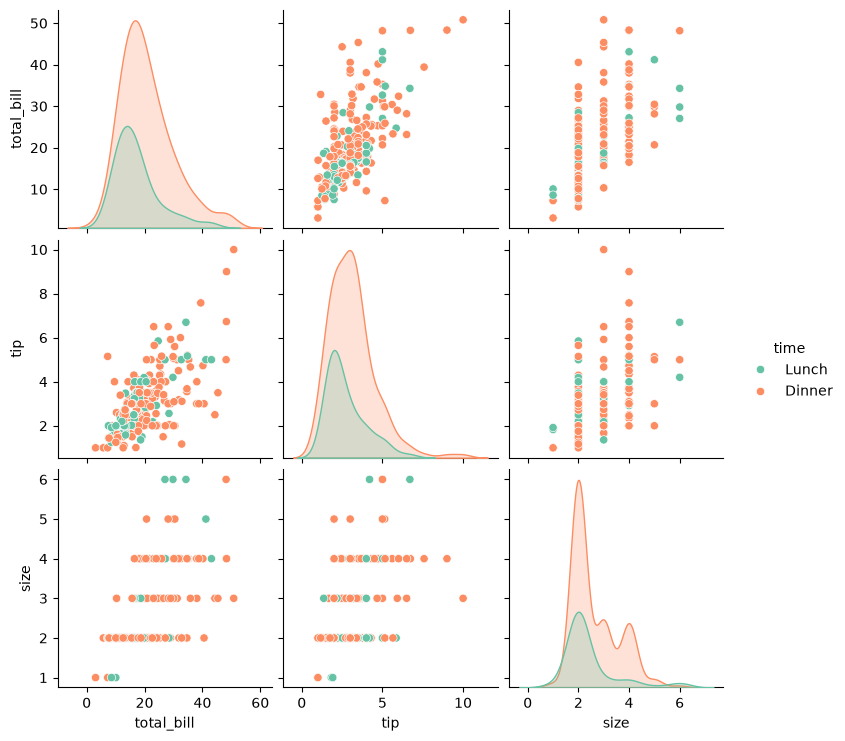

In [13]:
sns.pairplot(
    data=df,
    vars=["total_bill", "tip", "size"],
    hue="time",
    palette="Set2"
)

plt.show()

**What to observe:**
- Do higher total bills generally correspond to larger tips?
- Do Lunch and Dinner observations appear similarly distributed?

### Step 3 — Create a jointplot

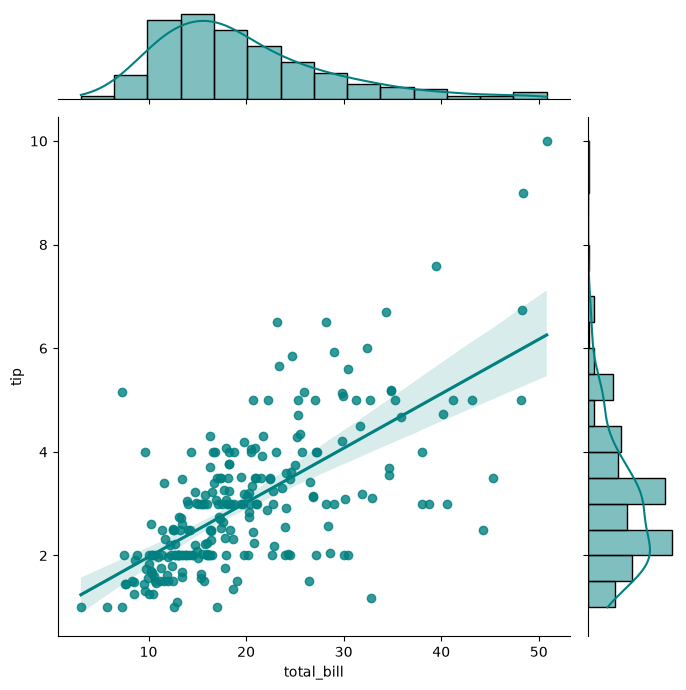

In [14]:
sns.jointplot(
    data=df,
    x="total_bill",
    y="tip",
    kind="reg",
    height=7,
    color="teal"
)

plt.show()

**What to observe:** Look at the central regression line and the marginal distributions along the top and right sides.

### Step 4 — Create a FacetGrid

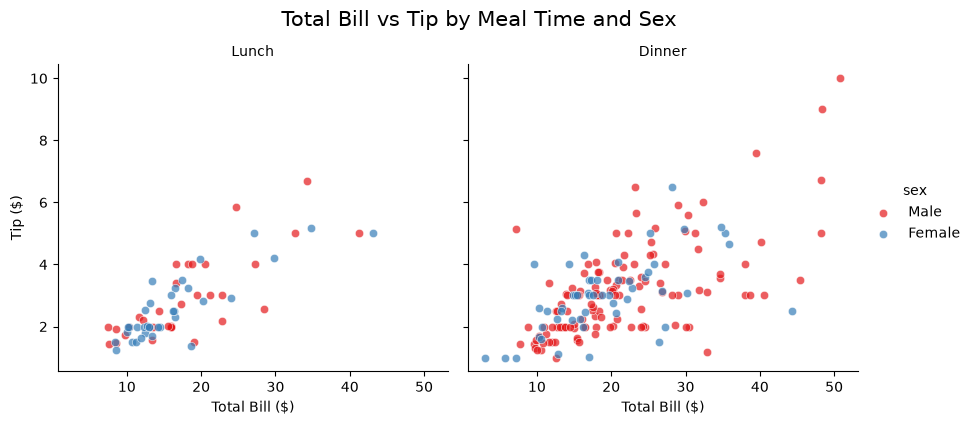

In [15]:
g = sns.FacetGrid(
    data=df,
    col="time",
    hue="sex",
    palette="Set1",
    height=4,
    aspect=1.1
)

g.map_dataframe(
    sns.scatterplot,
    x="total_bill",
    y="tip",
    alpha=0.7
)

g.add_legend()
g.set_axis_labels("Total Bill ($)", "Tip ($)")
g.set_titles("{col_name}")

g.figure.suptitle(
    "Total Bill vs Tip by Meal Time and Sex",
    y=1.05,
    fontsize=15
)

plt.show()

This produces separate Lunch and Dinner panels, with point colors distinguishing the sex categories.

### Step 5 — Understand the differences
| Function | Main purpose | Output |
| :--- | :--- | :--- |
| `pairplot()` | Relationships among several numerical variables | Matrix of plots |
| `jointplot()` | Relationship between two variables plus marginal distributions | One combined figure |
| `FacetGrid()` | Compare the same plot across categorical subsets | Grid of panels |

**Important:** `pairplot()` and `jointplot()` also manage their own figures. They aren't designed to be inserted into a regular `plt.subplots()` dashboard using `ax=`.

### Step 6 — Final practice challenge

In [17]:

from IPython.display import HTML, display

quiz_html = """
<div id="seaborn-day8-quiz" style="font-family: Arial, sans-serif; max-width: 750px; line-height: 1.6;">
    <p>Test your understanding of pairplot(), jointplot(), and FacetGrid().</p>

    <form id="quiz-form">

        <div style="margin-bottom: 22px;">
            <p><b>Q1. Which function is best for comparing several numerical variables in a matrix of plots?</b></p>
            <label><input type="radio" name="q1" value="a"> a) sns.jointplot()</label><br>
            <label><input type="radio" name="q1" value="b"> b) sns.pairplot()</label><br>
            <label><input type="radio" name="q1" value="c"> c) sns.FacetGrid() alone, without mapping a plot</label>
            <p id="feedback-q1"></p>
        </div>

        <div style="margin-bottom: 22px;">
            <p><b>Q2. Which function displays the relationship between two variables along with their marginal distributions?</b></p>
            <label><input type="radio" name="q2" value="a"> a) sns.jointplot()</label><br>
            <label><input type="radio" name="q2" value="b"> b) sns.pairplot()</label><br>
            <label><input type="radio" name="q2" value="c"> c) sns.countplot()</label>
            <p id="feedback-q2"></p>
        </div>

        <div style="margin-bottom: 22px;">
            <p><b>Q3. In a FacetGrid, what does hue="sex" control when used by the mapped plotting function?</b></p>
            <label><input type="radio" name="q3" value="a"> a) The number of rows in the grid</label><br>
            <label><input type="radio" name="q3" value="b"> b) The x-axis variable</label><br>
            <label><input type="radio" name="q3" value="c"> c) The colors assigned to sex categories</label>
            <p id="feedback-q3"></p>
        </div>

        <button type="button" id="submit-quiz"
            style="background:#2563eb; color:white; border:none; padding:10px 18px; border-radius:6px; cursor:pointer;">
            Submit Answers
        </button>

        <button type="button" id="reset-quiz"
            style="background:#e5e7eb; color:#111827; border:none; padding:10px 18px; border-radius:6px; cursor:pointer; margin-left:8px;">
            Reset
        </button>

        <h3 id="quiz-result"></h3>
    </form>

    <script>
    (function() {
        const root = document.getElementById("seaborn-day8-quiz");
        const answers = {q1: "b", q2: "a", q3: "c"};

        root.querySelector("#submit-quiz").addEventListener("click", function() {
            let score = 0;

            Object.keys(answers).forEach(function(question) {
                const selected = root.querySelector(
                    'input[name="' + question + '"]:checked'
                );
                const feedback = root.querySelector("#feedback-" + question);

                if (!selected) {
                    feedback.textContent = "Please select an answer.";
                    feedback.style.color = "#b45309";
                } else if (selected.value === answers[question]) {
                    score++;
                    feedback.textContent = "Correct!";
                    feedback.style.color = "#15803d";
                } else {
                    feedback.textContent = "Not quite. Try reviewing this function's purpose.";
                    feedback.style.color = "#b91c1c";
                }
            });

            root.querySelector("#quiz-result").textContent =
                "Your score: " + score + "/3";
        });

        root.querySelector("#reset-quiz").addEventListener("click", function() {
            root.querySelector("#quiz-form").reset();
            ["q1", "q2", "q3"].forEach(function(q) {
                root.querySelector("#feedback-" + q).textContent = "";
            });
            root.querySelector("#quiz-result").textContent = "";
        });
    })();
    </script>
</div>
"""

display(HTML(quiz_html))
